
# MindBloom: Data Preprocessing and Machine Learning

**Project Title:** A Web-Based System for Tracking Mood, Eating Behaviours and Predicting Relapse Risk in Anorexia Nervosa Among Teenagers and Young Adults

**Project:** MindBloom  
**Framework:** Django  
**Programming Language:** Python  
**Database:** MySQL  
**Machine Learning Environment:** Jupyter Notebook

---

## 1. Introduction

MindBloom is a web-based wellness monitoring system designed to collect and track mood, eating-related behaviours, and lifestyle information among teenagers and young adults.

The system includes:
- User registration and authentication.
- A Nutrition and Lifestyle Questionnaire.
- Daily mood and behavioural check-ins.
- A personalized dashboard displaying historical trends.
- A MySQL database for storing user submissions.

This notebook documents the exploratory machine-learning component of MindBloom.

## 2. Objectives

The objectives of this notebook are to:

1. Load and understand the selected dataset.
2. Inspect the structure, variables, and data types.
3. Identify missing values, duplicates, and potential data quality issues.
4. Explore behavioural patterns through descriptive statistics and visualizations.
5. Prepare suitable features for exploratory machine learning.
6. Train and evaluate an initial baseline model, where the data supports an appropriate prediction task.
7. Document the limitations of the dataset and modelling results.

## 3. Important Research Consideration

The long-term objective of MindBloom is to investigate relapse-risk prediction.

However, the currently explored dataset has not been verified as containing a clinically defined anorexia nervosa relapse outcome.

Therefore, the initial analysis is exploratory. Any baseline model trained using this dataset must not be presented as a validated clinical relapse-risk prediction model.


In [1]:

# ==========================================================
# MINDBLOOM: IMPORT REQUIRED LIBRARIES
# ==========================================================

# Path is used to manage file locations.
from pathlib import Path

# NumPy supports numerical calculations.
import numpy as np

# Pandas is used for data manipulation and analysis.
import pandas as pd

# Matplotlib is used to create graphs.
import matplotlib.pyplot as plt

# Seaborn provides statistical visualizations.
import seaborn as sns

# pyreadr allows Python to read RData files.
import pyreadr

# Configure visualization settings.
sns.set_theme(style="whitegrid")

# Display all columns when inspecting the dataset.
pd.set_option("display.max_columns", None)

print("All required libraries imported successfully!")


All required libraries imported successfully!



## 4. Dataset Description

### 4.1 Dataset Format

The exploratory dataset is stored in an R data file:

`EMAnwsub.Rdata`

RData files can contain one or more R objects, including data frames.

We use the Python library `pyreadr` to load the dataset into a Pandas DataFrame.

### 4.2 Why Ecological Momentary Assessment (EMA)?

Ecological Momentary Assessment involves collecting repeated measurements of participants' experiences and behaviours over time.

EMA data is relevant to MindBloom because the application also collects repeated daily check-ins, including:

- Mood levels.
- Stress levels.
- Sleep duration.
- Eating-related difficulties.
- Meal frequency.

The dataset is being investigated for exploratory behavioural analysis. Its variables, suitability, and limitations must be examined before selecting a prediction target.

### 4.3 Dataset Inspection

The next stage involves:

1. Locating the dataset file.
2. Loading the available R objects.
3. Identifying the main data frame.
4. Inspecting its dimensions and column names.


In [2]:

# ==========================================================
# STEP 1: LOCATE THE DATASET
# ==========================================================

# Display the current working directory.
current_directory = Path.cwd()

print("Current working directory:")
print(current_directory)

# Search the project folder and its subfolders for the dataset.
# The notebook is expected to be inside the 'notebooks' folder.
project_directory = current_directory.parent

dataset_files = list(
    project_directory.rglob("EMAnwsub.Rdata")
)

# Display any matching dataset files.
if dataset_files:
    print("\nDataset file(s) found:")

    for file in dataset_files:
        print(file)

else:
    print("\nDataset not found in the project folder.")
    print("Copy EMAnwsub.Rdata into a 'data' folder")
    print("inside the MindBloom-System project.")


Current working directory:
C:\Users\sigei\OneDrive\Documents\Year 4\4.2\IS Project II\MindBloom-System\notebooks

Dataset file(s) found:
C:\Users\sigei\OneDrive\Documents\Year 4\4.2\IS Project II\MindBloom-System\core\ml\data\EMAnwsub.Rdata



## 5. Loading the Dataset

### 5.1 Reading the RData File

The dataset is stored in the RData format, which is commonly used in the R programming language.

Since MindBloom's machine-learning component is being developed in Python, the `pyreadr` library is used to read the RData file.

An RData file may contain multiple objects. Therefore, we first inspect the available objects before selecting the appropriate dataset for analysis.

### Purpose of This Step

- Load the original dataset without modifying it.
- Identify the objects stored in the RData file.
- Convert the relevant object into a Pandas DataFrame.
- Confirm that the dataset can be accessed successfully.

**Expected outcome:** A successfully loaded dataset ready for initial exploration.


In [3]:

# ==========================================================
# STEP 2: LOAD THE EMA DATASET
# ==========================================================

# Use the dataset path identified in the previous step.
dataset_path = dataset_files[0]

# Read the RData file using pyreadr.
rdata_objects = pyreadr.read_r(str(dataset_path))

# Display the names of all objects stored in the file.
print("Objects found in the RData file:")
print(list(rdata_objects.keys()))

# Inspect each object's type and dimensions.
for object_name, object_value in rdata_objects.items():

    print(f"\nObject name: {object_name}")
    print(f"Object type: {type(object_value).__name__}")

    if isinstance(object_value, pd.DataFrame):
        print(f"Rows: {object_value.shape[0]}")
        print(f"Columns: {object_value.shape[1]}")


Objects found in the RData file:
['EMAnw.sub']

Object name: EMAnw.sub
Object type: DataFrame
Rows: 9792
Columns: 48


In [4]:

# ==========================================================
# STEP 3: CREATE A WORKING DATAFRAME
# ==========================================================

# Identify the DataFrame objects in the RData file.
dataframes = {
    name: value
    for name, value in rdata_objects.items()
    if isinstance(value, pd.DataFrame)
}

# Ensure at least one DataFrame was loaded.
if not dataframes:
    raise ValueError(
        "No Pandas DataFrame was found in the RData file."
    )

# Display the available DataFrames.
print("Available DataFrames:")
for name in dataframes:
    print("-", name)

# Select the first DataFrame as an initial candidate.
# We will verify its columns before confirming it is the
# appropriate dataset for our analysis.
selected_name = next(iter(dataframes))

# Create a copy to preserve the original loaded data.
df = dataframes[selected_name].copy()

print("\nSelected DataFrame:", selected_name)
print("Dataset shape:", df.shape)

# Display the first five observations.
display(df.head())


Available DataFrames:
- EMAnw.sub

Selected DataFrame: EMAnw.sub
Dataset shape: (9792, 48)


,ID,ComplianceEMA,Age,YearsOfEducation,BMI_sosci,FC,lApV,hApV,lAnV,hAnV,lApV_1,hApV_1,lAnV_1,hAnV_1,PA,NA,PA_1,NA_1,E_cheerful,E_enthusiastic,E_relaxed,E_calm,E_irritated,E_worried,E_depressed,E_bored,E_nervous_stressed,E_dissatisfied,E_tense,SEES_Happy,SEES_Sad,SEES_Anger,SEES_Anxiety,DEBQ_emo,EDEQ_gesamt,lApV_cwc,hApV_cwc,lAnV_cwc,hAnV_cwc,lApV_1_cwc,hApV_1_cwc,lAnV_1_cwc,hAnV_1_cwc,NA_cwc,PA_cwc,NA_1_cwc,PA_1_cwc,Group
0,222,89.583333,43.0,13.0,22.37568,40.0,52.0,51.0,0.75,0.000000,59.0,25.5,0.00,0.000000,51.50,0.428571,42.25,0.000000,52.0,50.0,52.0,52.0,0.0,0.0,0.0,3.0,0.0,0.0,0.0,1.8,3.8,3.0,3.2,43.0,3.1125,18.116279,22.034884,-5.976744,-13.232558,26.814286,-7.185714,-6.65,-13.600000,-9.086379,20.075581,-9.628571,9.814286,BED
1,222,89.583333,43.0,13.0,22.37568,57.0,78.0,49.5,0.00,0.000000,84.0,42.0,0.00,0.000000,63.75,0.000000,63.00,0.000000,59.0,40.0,80.0,76.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.8,3.8,3.0,3.2,43.0,3.1125,44.116279,20.534884,-6.726744,-13.232558,51.814286,9.314286,-6.65,-13.600000,-9.514950,32.325581,-9.628571,30.564286,BED
2,222,89.583333,43.0,13.0,22.37568,66.0,63.0,31.5,1.25,3.333333,0.0,0.0,34.75,51.666667,47.25,2.142857,0.00,42.000000,55.0,8.0,70.0,56.0,0.0,5.0,0.0,0.0,6.0,0.0,4.0,1.8,3.8,3.0,3.2,43.0,3.1125,29.116279,2.534884,-5.476744,-9.899225,-32.185714,-32.685714,28.10,38.066667,-7.372093,15.825581,32.371429,-32.435714,BED
3,222,89.583333,43.0,13.0,22.37568,0.0,100.0,50.0,0.25,2.333333,NaN,NaN,NaN,NaN,75.00,1.142857,NaN,NaN,100.0,0.0,100.0,100.0,7.0,1.0,0.0,0.0,0.0,0.0,0.0,1.8,3.8,3.0,3.2,43.0,3.1125,66.116279,21.034884,-6.476744,-10.899225,NaN,NaN,NaN,NaN,-8.372093,43.575581,NaN,NaN,BED
4,222,89.583333,43.0,13.0,22.37568,100.0,59.0,25.5,0.00,0.000000,26.0,50.0,1.50,0.000000,42.25,0.000000,38.00,0.857143,51.0,0.0,55.0,63.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.8,3.8,3.0,3.2,43.0,3.1125,25.116279,-3.465116,-6.726744,-13.232558,-6.185714,17.314286,-5.15,-13.600000,-9.514950,10.825581,-8.771429,5.564286,BED


In [5]:

# ==========================================================
# STEP 4: INITIAL DATASET INSPECTION
# ==========================================================

# Display all column names.
print("COLUMN NAMES:")
print(df.columns.tolist())

# Display dataset dimensions.
print("\nNUMBER OF ROWS:", df.shape[0])
print("NUMBER OF COLUMNS:", df.shape[1])

# Display each column's data type and non-null counts.
print("\nDATASET INFORMATION:")
df.info()

# Display descriptive statistics for numerical columns.
print("\nNUMERICAL SUMMARY:")
display(df.describe())

# Display a preview of the first five records.
print("\nFIRST FIVE RECORDS:")
display(df.head())


COLUMN NAMES:
['ID', 'ComplianceEMA', 'Age', 'YearsOfEducation', 'BMI_sosci', 'FC', 'lApV', 'hApV', 'lAnV', 'hAnV', 'lApV_1', 'hApV_1', 'lAnV_1', 'hAnV_1', 'PA', 'NA', 'PA_1', 'NA_1', 'E_cheerful', 'E_enthusiastic', 'E_relaxed', 'E_calm', 'E_irritated', 'E_worried', 'E_depressed', 'E_bored', 'E_nervous_stressed', 'E_dissatisfied', 'E_tense', 'SEES_Happy', 'SEES_Sad', 'SEES_Anger', 'SEES_Anxiety', 'DEBQ_emo', 'EDEQ_gesamt', 'lApV_cwc', 'hApV_cwc', 'lAnV_cwc', 'hAnV_cwc', 'lApV_1_cwc', 'hApV_1_cwc', 'lAnV_1_cwc', 'hAnV_1_cwc', 'NA_cwc', 'PA_cwc', 'NA_1_cwc', 'PA_1_cwc', 'Group']

NUMBER OF ROWS: 9792
NUMBER OF COLUMNS: 48

DATASET INFORMATION:
<class 'pandas.DataFrame'>
RangeIndex: 9792 entries, 0 to 9791
Data columns (total 48 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   ID                  9792 non-null   category
 1   ComplianceEMA       9792 non-null   float64 
 2   Age                 9792 non-null   float64 
 3  

,ComplianceEMA,Age,YearsOfEducation,BMI_sosci,FC,lApV,hApV,lAnV,hAnV,lApV_1,hApV_1,lAnV_1,hAnV_1,PA,NA,PA_1,NA_1,E_cheerful,E_enthusiastic,E_relaxed,E_calm,E_irritated,E_worried,E_depressed,E_bored,E_nervous_stressed,E_dissatisfied,E_tense,SEES_Happy,SEES_Sad,SEES_Anger,SEES_Anxiety,DEBQ_emo,EDEQ_gesamt,lApV_cwc,hApV_cwc,lAnV_cwc,hAnV_cwc,lApV_1_cwc,hApV_1_cwc,lAnV_1_cwc,hAnV_1_cwc,NA_cwc,PA_cwc,NA_1_cwc,PA_1_cwc
count,9792.000000,9792.000000,9744.000000,9792.000000,7904.000000,7904.000000,7904.000000,7904.000000,7904.000000,6307.000000,6307.000000,6307.000000,6307.000000,7904.000000,7904.000000,6581.000000,6581.000000,7904.000000,7904.000000,7904.000000,7904.000000,7904.000000,7904.000000,7904.000000,7904.000000,7904.000000,7904.000000,7904.000000,9744.000000,9744.000000,9744.000000,9744.000000,9792.000000,9744.000000,7.904000e+03,7.904000e+03,7.904000e+03,7.904000e+03,6.307000e+03,6.307000e+03,6.307000e+03,6.307000e+03,7.904000e+03,7.904000e+03,6.581000e+03,6.581000e+03
mean,80.718954,28.441176,14.502463,22.168814,34.260374,32.643535,21.656377,25.590366,24.397225,31.864199,21.750595,25.420366,25.084298,27.149956,25.079020,26.876880,25.295635,27.380061,15.932692,32.914221,32.372849,15.095774,26.486463,23.460526,14.315283,28.677632,38.099190,29.418269,2.828571,3.465025,2.899507,2.783251,38.607843,3.038485,-6.023072e-17,-1.438346e-17,1.887829e-17,8.944712e-17,6.421585e-17,7.942487e-17,-1.177291e-16,1.780018e-16,5.843279e-18,1.168656e-17,2.078400e-17,1.133673e-17
std,13.419041,11.466283,3.936423,6.614940,32.459995,28.434468,22.464956,21.151617,22.897372,28.018383,22.321978,21.025965,22.992137,23.189495,19.871747,23.003141,19.798685,27.599438,21.777452,30.000949,29.775775,22.216352,28.307597,29.318100,21.478074,28.651547,34.230291,29.300844,0.740276,0.985116,0.875405,0.930070,14.428825,1.581636,1.966857e+01,1.584398e+01,1.200138e+01,1.625425e+01,1.934333e+01,1.560634e+01,1.179780e+01,1.620080e+01,1.177206e+01,1.547929e+01,1.161360e+01,1.533621e+01
min,50.000000,14.000000,3.000000,11.554217,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,13.000000,0.162500,-7.897619e+01,-5.454167e+01,-5.421000e+01,-7.173016e+01,-7.844118e+01,-5.351786e+01,-4.606731e+01,-7.012745e+01,-4.907429e+01,-5.625000e+01,-4.889286e+01,-5.548077e+01
25%,70.833333,19.750000,12.000000,18.206645,3.000000,7.000000,3.000000,7.750000,5.333333,7.000000,3.250000,7.750000,6.333333,7.250000,8.857143,7.000000,9.285714,2.000000,0.000000,5.000000,5.000000,0.000000,0.000000,0.000000,0.000000,3.000000,6.000000,3.000000,2.200000,2.800000,2.200000,2.000000,27.000000,1.881250,-1.103571e+01,-8.651163e+00,-7.232143e+00,-9.952500e+00,-1.124194e+01,-8.657143e+00,-6.957143e+00,-9.893452e+00,-7.157143e+00,-8.891111e+00,-7.189189e+00,-8.865385e+00
50%,83.333333,23.000000,14.000000,20.723441,25.000000,25.500000,14.000000,21.250000,18.333333,25.000000,14.500000,21.000000,19.333333,21.500000,20.571429,21.250000,20.714286,18.000000,7.000000,25.000000,24.000000,6.000000,16.000000,10.000000,5.000000,20.000000,29.000000,20.000000,3.000000,3.600000,3.000000,2.600000,39.000000,3.231250,-1.534959e+00,-1.782609e+00,-1.256777e+00,-2.314286e+00,-1.662500e+00,-1.759259e+00,-1.393939e+00,-2.407407e+00,-1.424397e+00,-1.250000e+00,-1.476190e+00,-1.271739e+00
75%,91.666667,35.000000,16.000000,23.917702,62.000000,55.000000,35.000000,39.750000,38.000000,54.000000,35.000000,39.125000,38.333333,44.000000,38.428571,43.250000,38.571429,49.000000,23.000000,58.000000,57.000000,20.000000,45.000000,39.000000,20.000000,49.000000,67.000000,50.000000,3.200000,4.200000,3.600000,3.400000,50.000000,4.325000,1.233623e+01,6.733482e+00,6.357162e+00,8.269841e+00,1.190173e+01,6.750000e+00,6.000000e+00,8.359114e+00,6.309035e+00,8.577227e+00,6.290476e+00,8.466667e+00
max,100.000000,60.000000,38.000000,46.308816,100.000000,1


FIRST FIVE RECORDS:


,ID,ComplianceEMA,Age,YearsOfEducation,BMI_sosci,FC,lApV,hApV,lAnV,hAnV,lApV_1,hApV_1,lAnV_1,hAnV_1,PA,NA,PA_1,NA_1,E_cheerful,E_enthusiastic,E_relaxed,E_calm,E_irritated,E_worried,E_depressed,E_bored,E_nervous_stressed,E_dissatisfied,E_tense,SEES_Happy,SEES_Sad,SEES_Anger,SEES_Anxiety,DEBQ_emo,EDEQ_gesamt,lApV_cwc,hApV_cwc,lAnV_cwc,hAnV_cwc,lApV_1_cwc,hApV_1_cwc,lAnV_1_cwc,hAnV_1_cwc,NA_cwc,PA_cwc,NA_1_cwc,PA_1_cwc,Group
0,222,89.583333,43.0,13.0,22.37568,40.0,52.0,51.0,0.75,0.000000,59.0,25.5,0.00,0.000000,51.50,0.428571,42.25,0.000000,52.0,50.0,52.0,52.0,0.0,0.0,0.0,3.0,0.0,0.0,0.0,1.8,3.8,3.0,3.2,43.0,3.1125,18.116279,22.034884,-5.976744,-13.232558,26.814286,-7.185714,-6.65,-13.600000,-9.086379,20.075581,-9.628571,9.814286,BED
1,222,89.583333,43.0,13.0,22.37568,57.0,78.0,49.5,0.00,0.000000,84.0,42.0,0.00,0.000000,63.75,0.000000,63.00,0.000000,59.0,40.0,80.0,76.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.8,3.8,3.0,3.2,43.0,3.1125,44.116279,20.534884,-6.726744,-13.232558,51.814286,9.314286,-6.65,-13.600000,-9.514950,32.325581,-9.628571,30.564286,BED
2,222,89.583333,43.0,13.0,22.37568,66.0,63.0,31.5,1.25,3.333333,0.0,0.0,34.75,51.666667,47.25,2.142857,0.00,42.000000,55.0,8.0,70.0,56.0,0.0,5.0,0.0,0.0,6.0,0.0,4.0,1.8,3.8,3.0,3.2,43.0,3.1125,29.116279,2.534884,-5.476744,-9.899225,-32.185714,-32.685714,28.10,38.066667,-7.372093,15.825581,32.371429,-32.435714,BED
3,222,89.583333,43.0,13.0,22.37568,0.0,100.0,50.0,0.25,2.333333,NaN,NaN,NaN,NaN,75.00,1.142857,NaN,NaN,100.0,0.0,100.0,100.0,7.0,1.0,0.0,0.0,0.0,0.0,0.0,1.8,3.8,3.0,3.2,43.0,3.1125,66.116279,21.034884,-6.476744,-10.899225,NaN,NaN,NaN,NaN,-8.372093,43.575581,NaN,NaN,BED
4,222,89.583333,43.0,13.0,22.37568,100.0,59.0,25.5,0.00,0.000000,26.0,50.0,1.50,0.000000,42.25,0.000000,38.00,0.857143,51.0,0.0,55.0,63.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.8,3.8,3.0,3.2,43.0,3.1125,25.116279,-3.465116,-6.726744,-13.232558,-6.185714,17.314286,-5.15,-13.600000,-9.514950,10.825581,-8.771429,5.564286,BED



## 6. Data Quality Assessment and Preprocessing

### 6.1 Introduction

Data preprocessing is the process of examining, cleaning, and preparing raw data before using it for statistical analysis or machine learning.

This stage is important because real-world datasets may contain:

- Missing values
- Duplicate records
- Incorrect or inconsistent data types
- Outliers and unusual observations
- Irrelevant variables
- Repeated observations from the same participant

### Objectives

The objectives of this stage are to:

1. Identify missing values in the dataset.
2. Examine duplicate observations.
3. Inspect data types and potential inconsistencies.
4. Identify participant identifiers and repeated measurements.
5. Investigate unusual numerical values.
6. Determine appropriate cleaning strategies.

### Research Consideration

Because the EMA dataset contains repeated measurements, observations from the same participant may be related.

Therefore, preprocessing and model evaluation must account for the dataset's longitudinal structure to reduce the risk of data leakage.

**Important:** This section initially identifies data quality issues. Cleaning decisions will be made after examining the results.


In [6]:

# ==========================================================
# STEP 5: IDENTIFY MISSING VALUES
# ==========================================================

# Count missing values in each column.
missing_count = df.isnull().sum()

# Calculate the percentage of missing values per column.
missing_percentage = (missing_count / len(df)) * 100

# Combine the results into a summary table.
missing_summary = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage (%)": missing_percentage
})

# Sort columns from highest to lowest missing percentage.
missing_summary = missing_summary.sort_values(
    by="Missing Percentage (%)",
    ascending=False
)

# Display only columns with missing values.
print("COLUMNS CONTAINING MISSING VALUES:")

display(
    missing_summary[
        missing_summary["Missing Values"] > 0
    ]
)

# Calculate overall missing data.
total_missing = df.isnull().sum().sum()

print("\nTotal missing values:", total_missing)
print("Total observations:", len(df))


COLUMNS CONTAINING MISSING VALUES:


,Missing Values,Missing Percentage (%)
lAnV_1,3485,35.590278
hAnV_1,3485,35.590278
lApV_1,3485,35.590278
hApV_1,3485,35.590278
lApV_1_cwc,3485,35.590278
hAnV_1_cwc,3485,35.590278
lAnV_1_cwc,3485,35.590278
hApV_1_cwc,3485,35.590278
NA_1_cwc,3211,32.792075
PA_1_cwc,3211,32.792075



Total missing values: 86324
Total observations: 9792


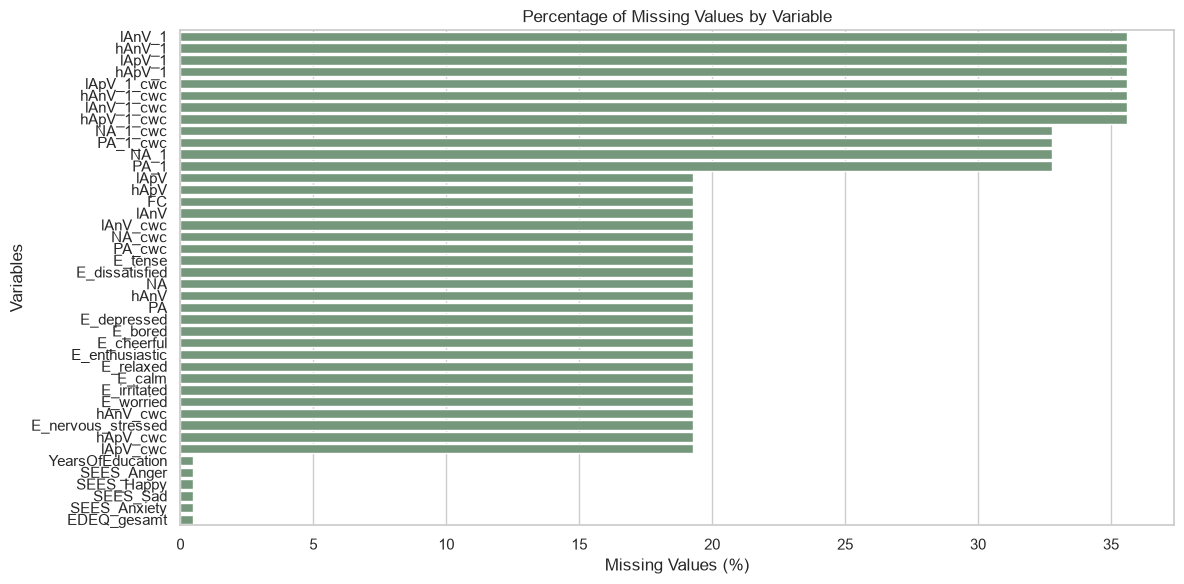

In [7]:

# ==========================================================
# STEP 6: VISUALIZE MISSING DATA
# ==========================================================

# Select columns containing at least one missing value.
missing_columns = missing_summary[
    missing_summary["Missing Values"] > 0
]

if not missing_columns.empty:

    plt.figure(figsize=(12, 6))

    sns.barplot(
        x=missing_columns["Missing Percentage (%)"],
        y=missing_columns.index,
        color="#6F9E78"
    )

    plt.title("Percentage of Missing Values by Variable")
    plt.xlabel("Missing Values (%)")
    plt.ylabel("Variables")

    plt.tight_layout()
    plt.show()

else:
    print("No missing values were identified.")


In [8]:

# ==========================================================
# STEP 7: CHECK FOR DUPLICATE RECORDS
# ==========================================================

# Count rows that are identical across all columns.
duplicate_count = df.duplicated().sum()

# Calculate the percentage of exact duplicates.
duplicate_percentage = (
    duplicate_count / len(df) * 100
    if len(df) > 0 else 0
)

print("Exact duplicate rows:", duplicate_count)

print(
    "Percentage of duplicate rows:",
    round(duplicate_percentage, 2),
    "%"
)

# Display duplicate rows if any exist.
if duplicate_count > 0:

    print("\nSample duplicate records:")

    display(
        df[df.duplicated(keep=False)].head(10)
    )

else:
    print("\nNo exact duplicate rows were identified.")


Exact duplicate rows: 788
Percentage of duplicate rows: 8.05 %

Sample duplicate records:


,ID,ComplianceEMA,Age,YearsOfEducation,BMI_sosci,FC,lApV,hApV,lAnV,hAnV,lApV_1,hApV_1,lAnV_1,hAnV_1,PA,NA,PA_1,NA_1,E_cheerful,E_enthusiastic,E_relaxed,E_calm,E_irritated,E_worried,E_depressed,E_bored,E_nervous_stressed,E_dissatisfied,E_tense,SEES_Happy,SEES_Sad,SEES_Anger,SEES_Anxiety,DEBQ_emo,EDEQ_gesamt,lApV_cwc,hApV_cwc,lAnV_cwc,hAnV_cwc,lApV_1_cwc,hApV_1_cwc,lAnV_1_cwc,hAnV_1_cwc,NA_cwc,PA_cwc,NA_1_cwc,PA_1_cwc,Group
134,234,83.333333,45.0,16.0,20.820940,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,3.8,2.2,2.4,34.0,0.8125,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CG
138,234,83.333333,45.0,16.0,20.820940,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,3.8,2.2,2.4,34.0,0.8125,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CG
149,238,72.916667,28.0,20.0,27.548209,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.6,4.4,4.0,4.8,59.0,2.9375,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,BED
151,238,72.916667,28.0,20.0,27.548209,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.6,4.4,4.0,4.8,59.0,2.9375,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,BED
158,238,72.916667,28.0,20.0,27.548209,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.6,4.4,4.0,4.8,59.0,2.9375,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,BED
162,238,72.916667,28.0,20.0,27.548209,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.6,4.4,4.0,4.8,59.0,2.9375,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,BED
164,238,72.916667,28.0,20.0,27.548209,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.6,4.4,4.0,4.8,59.0,2.9375,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,BED
171,238,72.916667,28.0,20.0,27.548209,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.6,4.4,4.0,4.8,59.0,2.9375,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,BED
213,239,77.083333,48.0,22.0,20.756387,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,4.0,4.0,4.0,52.0,3.4625,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,BED
215,239,77.083333,48.0,22.0,20.756387,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,4.0,4.0,4.0,52.0,3.4625,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,BED


In [9]:

# ==========================================================
# STEP 8: EXAMINE DATA TYPES
# ==========================================================

# Display each column and its data type.
data_types = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Non-Null Count": df.notnull().sum().values
})

display(data_types)

# Separate numerical and non-numerical columns.
numerical_columns = df.select_dtypes(
    include=["number"]
).columns.tolist()

non_numerical_columns = df.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("\nNumber of numerical columns:", len(numerical_columns))

print("Number of non-numerical columns:", len(non_numerical_columns))

print("\nNumerical columns:")
print(numerical_columns)

print("\nNon-numerical columns:")
print(non_numerical_columns)


,Column,Data Type,Non-Null Count
0,ID,category,9792
1,ComplianceEMA,float64,9792
2,Age,float64,9792
3,YearsOfEducation,float64,9744
4,BMI_sosci,float64,9792
5,FC,float64,7904
6,lApV,float64,7904
7,hApV,float64,7904
8,lAnV,float64,7904
9,hAnV,float64,7904



Number of numerical columns: 46
Number of non-numerical columns: 2

Numerical columns:
['ComplianceEMA', 'Age', 'YearsOfEducation', 'BMI_sosci', 'FC', 'lApV', 'hApV', 'lAnV', 'hAnV', 'lApV_1', 'hApV_1', 'lAnV_1', 'hAnV_1', 'PA', 'NA', 'PA_1', 'NA_1', 'E_cheerful', 'E_enthusiastic', 'E_relaxed', 'E_calm', 'E_irritated', 'E_worried', 'E_depressed', 'E_bored', 'E_nervous_stressed', 'E_dissatisfied', 'E_tense', 'SEES_Happy', 'SEES_Sad', 'SEES_Anger', 'SEES_Anxiety', 'DEBQ_emo', 'EDEQ_gesamt', 'lApV_cwc', 'hApV_cwc', 'lAnV_cwc', 'hAnV_cwc', 'lApV_1_cwc', 'hApV_1_cwc', 'lAnV_1_cwc', 'hAnV_1_cwc', 'NA_cwc', 'PA_cwc', 'NA_1_cwc', 'PA_1_cwc']

Non-numerical columns:
['ID', 'Group']


In [10]:

# ==========================================================
# STEP 9: IDENTIFY LONGITUDINAL DATA STRUCTURE
# ==========================================================

# Search for possible participant identifier columns.
possible_id_columns = [
    col for col in df.columns
    if any(
        keyword in col.lower()
        for keyword in [
            "participant", "subject", "person", "patient", "id"
        ]
    )
]

# Search for possible time-related columns.
possible_time_columns = [
    col for col in df.columns
    if any(
        keyword in col.lower()
        for keyword in [
            "time", "date", "day", "week", "moment"
        ]
    )
]

print("Possible participant identifier columns:")
print(possible_id_columns)

print("\nPossible time-related columns:")
print(possible_time_columns)

# These are candidate columns only.
# Their meaning must be verified before using them.


Possible participant identifier columns:
['ID']

Possible time-related columns:
[]



### 6.2 Data Quality Assessment Summary

The initial data quality assessment examines:

1. **Missing values:** The number and percentage of missing entries in each variable.
2. **Duplicate records:** Whether any rows are exactly identical.
3. **Data types:** Whether variables have appropriate numerical, categorical, or date/time representations.
4. **Longitudinal structure:** Potential participant identifiers and time-related variables.
5. **Data cleaning requirements:** Issues requiring further investigation before transformation.

### Key Considerations

- Missing values should not automatically be replaced with zero.
- Repeated participant IDs are expected in longitudinal datasets.
- Exact duplicate rows should be investigated before deletion.
- Participant identifiers should not be treated as ordinary numerical predictors.
- Data preprocessing decisions should be documented and justified.

### Next Stage

The next stage will involve examining the actual variables and their distributions, identifying relevant features, and deciding how missing values and other data quality issues should be handled.



## 7. Data Cleaning and Feature Selection

### 7.1 Introduction

Data cleaning prepares raw observations for reliable analysis and machine learning.

The purpose of this stage is to identify and address data quality problems while preserving meaningful information.

### Main Activities

1. Create a working copy of the original dataset.
2. Examine missing values and their patterns.
3. Identify potential participant identifiers.
4. Investigate numerical distributions and unusual values.
5. Identify potential predictor variables.
6. Document preprocessing decisions before model training.

### Important Considerations

The EMA dataset contains repeated measurements. Therefore, observations from the same participant may be related.

Repeated participant identifiers should not be treated as duplicate records.

Missing values should also be handled carefully because an unanswered questionnaire item is not necessarily equivalent to a numerical value of zero.

The initial cleaning stage will not automatically delete observations, replace missing values, or remove outliers.

These decisions will be made after examining the variables and understanding their meanings.


In [11]:

# ==========================================================
# STEP 10: CREATE A WORKING DATASET
# ==========================================================

# Preserve the original DataFrame for comparison.
df_original = df.copy(deep=True)

# Create a separate DataFrame for preprocessing.
df_clean = df.copy(deep=True)

print("Original dataset shape:", df_original.shape)
print("Working dataset shape:", df_clean.shape)

# Check whether any changes have been made.
print(
    "Datasets currently identical:",
    df_original.equals(df_clean)
)


Original dataset shape: (9792, 48)
Working dataset shape: (9792, 48)
Datasets currently identical: True


In [12]:

# ==========================================================
# STEP 11: EXPLORE NUMERICAL VARIABLES
# ==========================================================

# Identify numerical columns.
numeric_features = df_clean.select_dtypes(
    include=["number"]
).columns.tolist()

print("Number of numerical variables:", len(numeric_features))

# Generate descriptive statistics.
if numeric_features:

    numerical_summary = df_clean[
        numeric_features
    ].describe().T

    display(numerical_summary)

else:
    print("No numerical variables found.")


Number of numerical variables: 46


,count,mean,std,min,25%,50%,75%,max
ComplianceEMA,9792.0,8.071895e+01,13.419041,50.000000,70.833333,83.333333,91.666667,100.000000
Age,9792.0,2.844118e+01,11.466283,14.000000,19.750000,23.000000,35.000000,60.000000
YearsOfEducation,9744.0,1.450246e+01,3.936423,3.000000,12.000000,14.000000,16.000000,38.000000
BMI_sosci,9792.0,2.216881e+01,6.614940,11.554217,18.206645,20.723441,23.917702,46.308816
FC,7904.0,3.426037e+01,32.459995,0.000000,3.000000,25.000000,62.000000,100.000000
lApV,7904.0,3.264353e+01,28.434468,0.000000,7.000000,25.500000,55.000000,100.000000
hApV,7904.0,2.165638e+01,22.464956,0.000000,3.000000,14.000000,35.000000,100.000000
lAnV,7904.0,2.559037e+01,21.151617,0.000000,7.750000,21.250000,39.750000,100.000000
hAnV,7904.0,2.439723e+01,22.897372,0.000000,5.333333,18.333333,38.000000,100.000000
lApV_1,6307.0,3.186420e+01,28.018383,0.000000,7.000000,25.000000,54.000000,100.000000


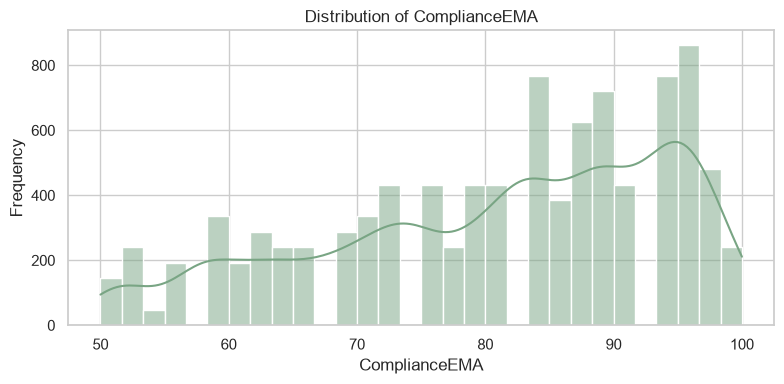

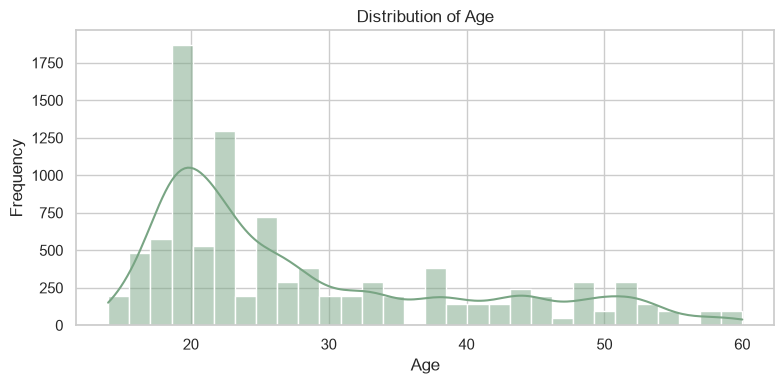

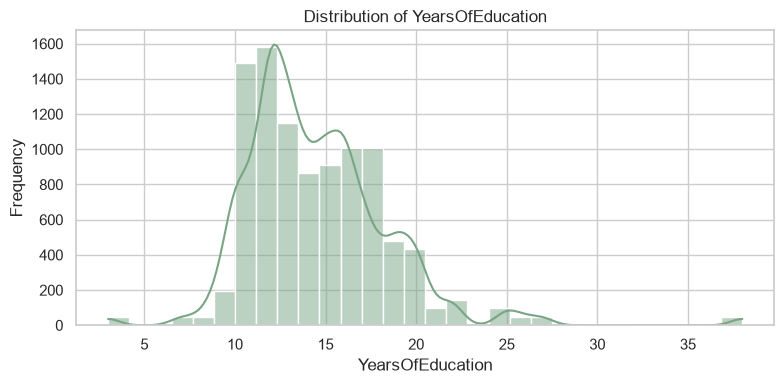

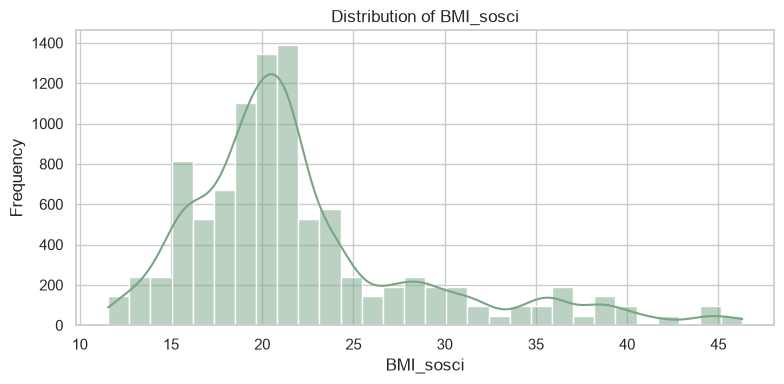

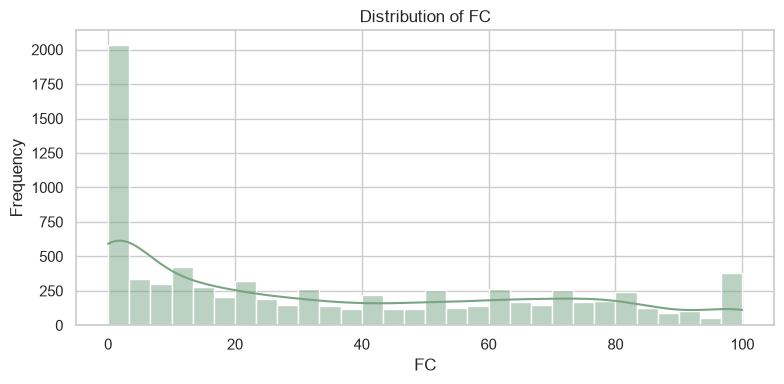

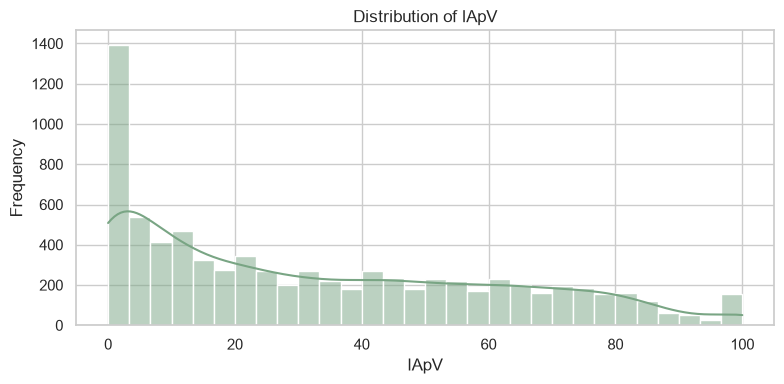

In [13]:

# ==========================================================
# STEP 12: VISUALIZE NUMERICAL DISTRIBUTIONS
# ==========================================================

# Limit the first visualization to six variables.
# We will review their meanings before deciding which
# variables are appropriate for modelling.

features_to_plot = numeric_features[:6]

if features_to_plot:

    for column in features_to_plot:

        plt.figure(figsize=(8, 4))

        sns.histplot(
            data=df_clean,
            x=column,
            bins=30,
            kde=True,
            color="#79A584"
        )

        plt.title(f"Distribution of {column}")
        plt.xlabel(column)
        plt.ylabel("Frequency")

        plt.tight_layout()
        plt.show()

else:
    print("No numerical variables available for plotting.")


In [14]:

# ==========================================================
# STEP 13: REVIEW MISSING-VALUE PATTERNS
# ==========================================================

# Calculate missing values in the working dataset.
missing_counts = df_clean.isna().sum()

missing_percentages = (
    df_clean.isna().mean() * 100
)

# Create a summary table.
cleaning_report = pd.DataFrame({
    "Missing Count": missing_counts,
    "Missing Percentage": missing_percentages
})

# Sort by missing percentage.
cleaning_report = cleaning_report.sort_values(
    "Missing Percentage",
    ascending=False
)

display(cleaning_report)

# Identify columns with more than 20% missing values.
high_missing_columns = cleaning_report[
    cleaning_report["Missing Percentage"] > 20
]

print("Variables with more than 20% missing data:")

display(high_missing_columns)


,Missing Count,Missing Percentage
lAnV_1,3485,35.590278
hAnV_1,3485,35.590278
lApV_1,3485,35.590278
hApV_1,3485,35.590278
lApV_1_cwc,3485,35.590278
hAnV_1_cwc,3485,35.590278
lAnV_1_cwc,3485,35.590278
hApV_1_cwc,3485,35.590278
NA_1_cwc,3211,32.792075
PA_1_cwc,3211,32.792075


Variables with more than 20% missing data:


,Missing Count,Missing Percentage
lAnV_1,3485,35.590278
hAnV_1,3485,35.590278
lApV_1,3485,35.590278
hApV_1,3485,35.590278
lApV_1_cwc,3485,35.590278
hAnV_1_cwc,3485,35.590278
lAnV_1_cwc,3485,35.590278
hApV_1_cwc,3485,35.590278
NA_1_cwc,3211,32.792075
PA_1_cwc,3211,32.792075


In [15]:

# ==========================================================
# STEP 14: IDENTIFY POSSIBLE FEATURE GROUPS
# ==========================================================

# These keywords are used to discover candidate variables.
# Matches are not automatically accepted as predictors.

feature_keywords = {
    "Mood and Emotions": [
        "mood", "emotion", "affect", "sad", "anxiety",
        "stress", "happy"
    ],

    "Eating Behaviour": [
        "eat", "food", "meal", "crav", "hunger",
        "binge", "restrict"
    ],

    "Sleep and Lifestyle": [
        "sleep", "activity", "exercise", "energy"
    ],

    "Time and Participant": [
        "time", "date", "day", "week",
        "participant", "subject", "id"
    ]
}

# Store candidate columns by category.
feature_groups = {}

for group_name, keywords in feature_keywords.items():

    matched_columns = [
        col for col in df_clean.columns
        if any(
            keyword in col.lower()
            for keyword in keywords
        )
    ]

    feature_groups[group_name] = matched_columns

    print(f"\n{group_name}:")
    print(matched_columns)



Mood and Emotions:
['E_nervous_stressed', 'SEES_Happy', 'SEES_Sad', 'SEES_Anxiety']

Eating Behaviour:
[]

Sleep and Lifestyle:
[]

Time and Participant:
['ID']


In [16]:

# ==========================================================
# STEP 15: PREPARE A FEATURE REVIEW TABLE
# ==========================================================

# Create a table describing each variable.
feature_review = pd.DataFrame({
    "Variable": df_clean.columns,
    "Data Type": df_clean.dtypes.astype(str).values,
    "Missing (%)": (
        df_clean.isna().mean().values * 100
    ).round(2),
    "Unique Values": [
        df_clean[col].nunique(dropna=True)
        for col in df_clean.columns
    ]
})

# Add a placeholder for the variable's role.
feature_review["Proposed Role"] = "Needs review"

# Add a placeholder for interpretation.
feature_review["Notes"] = ""

display(feature_review)


,Variable,Data Type,Missing (%),Unique Values,Proposed Role,Notes
0,ID,category,0.00,204,Needs review,
1,ComplianceEMA,float64,0.00,25,Needs review,
2,Age,float64,0.00,42,Needs review,
3,YearsOfEducation,float64,0.49,23,Needs review,
4,BMI_sosci,float64,0.00,188,Needs review,
5,FC,float64,19.28,101,Needs review,
6,lApV,float64,19.28,200,Needs review,
7,hApV,float64,19.28,194,Needs review,
8,lAnV,float64,19.28,353,Needs review,
9,hAnV,float64,19.28,296,Needs review,



### 7.2 Preliminary Data Cleaning Decisions

The following decisions guide the preprocessing process:

| Data Quality Issue | Initial Decision | Reason |
|---|---|---|
| Missing values | Investigate before imputation | Avoid introducing misleading values |
| Exact duplicates | Review before removal | Repeated assessments may be legitimate |
| Participant IDs | Preserve for grouping | Required for longitudinal analysis |
| Numerical outliers | Investigate before removal | Extreme responses may be meaningful |
| Categorical variables | Review before encoding | Encoding depends on variable meaning |
| Feature selection | Verify against dataset documentation | Prevent irrelevant or misleading predictors |
| Scaling | Fit only on training data | Prevent data leakage |

### 7.3 Current Status

At this stage, the notebook has:

- Created a working copy of the dataset.
- Examined numerical distributions.
- Reviewed missing-value patterns.
- Identified candidate feature groups.
- Generated a feature review table.

No automatic imputation, outlier removal, or model training has been performed in this section.

### Next Stage

The next step is to identify the correct participant identifier, verify the target variable, and prepare an appropriate training and testing strategy.



## 8. Feature Selection and Target Definition

### 8.1 Feature Selection

Feature selection is the process of identifying input variables that may help a machine-learning model predict an outcome.

In MindBloom, potential predictors may include:

- Emotional or mood-related measurements.
- Eating-related behaviours.
- Food craving measurements.
- Sleep or lifestyle information.
- Changes in behavioural measurements over time.

The final selection depends on the variables available in the dataset and their documented meanings.

### 8.2 Target Variable

The target variable is the outcome that the machine-learning model attempts to predict.

MindBloom's long-term objective is anorexia nervosa relapse-risk prediction.

However, the exploratory EMA dataset has not yet been verified as containing a clinically defined relapse outcome.

Therefore, we must distinguish between:

1. **Exploratory prediction:** Predicting an available behavioural measurement to test the modelling pipeline.
2. **Relapse-risk prediction:** Predicting a clinically meaningful relapse outcome, which requires an appropriately labelled dataset and validation.

A behavioural proxy should not be presented as a confirmed relapse label.

### 8.3 Preventing Data Leakage

Data leakage occurs when information unavailable at prediction time influences model training or evaluation.

Because EMA data contains repeated observations, records from the same participant may be correlated.

A participant-aware split can help evaluate whether a model generalizes to participants not seen during training.

If the intended application is forecasting future observations for an existing participant, a chronological evaluation strategy may also be needed.


In [17]:

# ==========================================================
# STEP 16: REVIEW CANDIDATE FEATURES
# ==========================================================

# Display all available columns with their data types.
candidate_features = pd.DataFrame({
    "Feature": df_clean.columns,
    "Data Type": df_clean.dtypes.astype(str).values,
    "Missing (%)": (
        df_clean.isna().mean().values * 100
    ).round(2)
})

# Identify numeric features that could potentially
# be used in exploratory modelling.
numeric_candidates = df_clean.select_dtypes(
    include=["number"]
).columns.tolist()

print("AVAILABLE NUMERIC CANDIDATES:")
print(numeric_candidates)

print("\nFULL FEATURE REVIEW:")
display(candidate_features)

# Important:
# Numerical variables are not automatically suitable predictors.
# Participant IDs, future measurements and target-derived
# variables must be excluded where appropriate.


AVAILABLE NUMERIC CANDIDATES:
['ComplianceEMA', 'Age', 'YearsOfEducation', 'BMI_sosci', 'FC', 'lApV', 'hApV', 'lAnV', 'hAnV', 'lApV_1', 'hApV_1', 'lAnV_1', 'hAnV_1', 'PA', 'NA', 'PA_1', 'NA_1', 'E_cheerful', 'E_enthusiastic', 'E_relaxed', 'E_calm', 'E_irritated', 'E_worried', 'E_depressed', 'E_bored', 'E_nervous_stressed', 'E_dissatisfied', 'E_tense', 'SEES_Happy', 'SEES_Sad', 'SEES_Anger', 'SEES_Anxiety', 'DEBQ_emo', 'EDEQ_gesamt', 'lApV_cwc', 'hApV_cwc', 'lAnV_cwc', 'hAnV_cwc', 'lApV_1_cwc', 'hApV_1_cwc', 'lAnV_1_cwc', 'hAnV_1_cwc', 'NA_cwc', 'PA_cwc', 'NA_1_cwc', 'PA_1_cwc']

FULL FEATURE REVIEW:


,Feature,Data Type,Missing (%)
0,ID,category,0.00
1,ComplianceEMA,float64,0.00
2,Age,float64,0.00
3,YearsOfEducation,float64,0.49
4,BMI_sosci,float64,0.00
5,FC,float64,19.28
6,lApV,float64,19.28
7,hApV,float64,19.28
8,lAnV,float64,19.28
9,hAnV,float64,19.28


In [18]:

# ==========================================================
# STEP 17: IDENTIFY POSSIBLE EXPLORATORY TARGETS
# ==========================================================

target_keywords = [
    "crav",
    "urge",
    "eat",
    "food",
    "mood",
    "stress",
    "affect"
]

possible_targets = [
    col for col in df_clean.columns
    if any(
        keyword in col.lower()
        for keyword in target_keywords
    )
]

print("POSSIBLE EXPLORATORY TARGET VARIABLES:")

for col in possible_targets:
    print(
        f"{col} | "
        f"Type: {df_clean[col].dtype} | "
        f"Missing: {df_clean[col].isna().sum()}"
    )

if not possible_targets:
    print("No matching columns found.")

# We will verify the meaning of the target
# before choosing a modelling approach.


POSSIBLE EXPLORATORY TARGET VARIABLES:
E_nervous_stressed | Type: float64 | Missing: 1888


In [19]:

# ==========================================================
# STEP 18: INSPECT PARTICIPANT IDENTIFIERS
# ==========================================================

possible_id_columns = [
    col for col in df_clean.columns
    if any(
        keyword in col.lower()
        for keyword in [
            "participant",
            "subject",
            "patient",
            "person",
            "id"
        ]
    )
]

print("POSSIBLE PARTICIPANT ID COLUMNS:")

for col in possible_id_columns:

    print(f"\nColumn: {col}")

    print(
        "Unique values:",
        df_clean[col].nunique(dropna=True)
    )

    print(
        "Missing values:",
        df_clean[col].isna().sum()
    )

    print("Sample values:")

    display(df_clean[col].head(10))


POSSIBLE PARTICIPANT ID COLUMNS:

Column: ID
Unique values: 204
Missing values: 0
Sample values:


0    222
1    222
2    222
3    222
4    222
5    222
6    222
7    222
8    222
9    222
Name: ID, dtype: category
Categories (204, str): ['222', '232', '234', '238', ..., '848', '850', '854', '860']


# ==========================================================
# STEP 19: PREPARE PARTICIPANT-AWARE SPLITTING
# ==========================================================

from sklearn.model_selection import GroupShuffleSplit

# GroupShuffleSplit separates groups rather than
# randomly distributing individual observations.
#
# This is useful for repeated-measures datasets
# because the same participant should not appear
# in both training and testing sets when evaluating
# generalization to unseen participants.

group_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

print("Participant-aware splitting method initialized.")

print("Training proportion: approximately 80%")
print("Testing proportion: approximately 20%")

print(
    "\nThe split has NOT been executed yet."
    "\nWe must first confirm the participant ID "
    "and the exploratory prediction target."
)



### 8.4 Feature Selection and Data Splitting Summary

The following activities have been completed in this stage:

1. Reviewed numerical variables as possible model inputs.
2. Identified candidate exploratory target variables.
3. Inspected potential participant identifiers.
4. Initialized a participant-aware data splitting method.

### Decisions Still Required

Before model training, the following must be confirmed:

- The correct participant identifier.
- The meaning of the selected exploratory target.
- Which variables are available at prediction time.
- Which features are appropriate predictors.
- Whether missing values require imputation.
- Whether scaling or categorical encoding is necessary.

### Important Limitation

No clinically validated anorexia nervosa relapse target has been established from this dataset.

Any initial model will therefore be described as an exploratory behavioural prediction model, not a clinical relapse-risk predictor.



## 9. Exploratory Model Development

### 9.1 Target Variable Selection

Following dataset inspection, the variable `E_nervous_stressed` was identified as a potential exploratory prediction target.

The variable is stored as `float64`, indicating that its values are numerical.

For this experiment, the objective is to investigate whether other suitable measurements in the dataset can predict the recorded nervousness or stress-related score.

### Why Regression?

Regression is appropriate when the target represents a meaningful numerical measurement.

Before training, we must confirm that the target's coding and measurement scale support a regression approach.

### Participant Identification

The variable `ID` identifies participants.

The dataset contains 204 unique participant identifiers, with no missing values in the ID column.

Because participants contribute repeated observations, we will split the dataset by participant rather than randomly splitting individual rows.

### Handling Missing Target Values

The target variable contains 1,888 missing values.

For supervised regression, observations without a known target cannot directly contribute to model fitting or conventional evaluation.

We will exclude these observations from this specific modelling experiment while preserving the original dataset.

### Research Limitation

This experiment investigates a stress-related measurement. It does not predict clinical relapse or establish anorexia nervosa relapse risk.


TARGET VARIABLE SUMMARY:


count    7904.000000
mean       28.677632
std        28.651547
min         0.000000
25%         3.000000
50%        20.000000
75%        49.000000
max       100.000000
Name: E_nervous_stressed, dtype: float64


TARGET VALUE FREQUENCIES:


E_nervous_stressed
0.0      1681
1.0       169
2.0       103
3.0        86
4.0       101
         ... 
97.0        8
98.0        7
99.0       12
100.0     239
NaN      1888
Name: count, Length: 102, dtype: int64


Missing target values: 1888


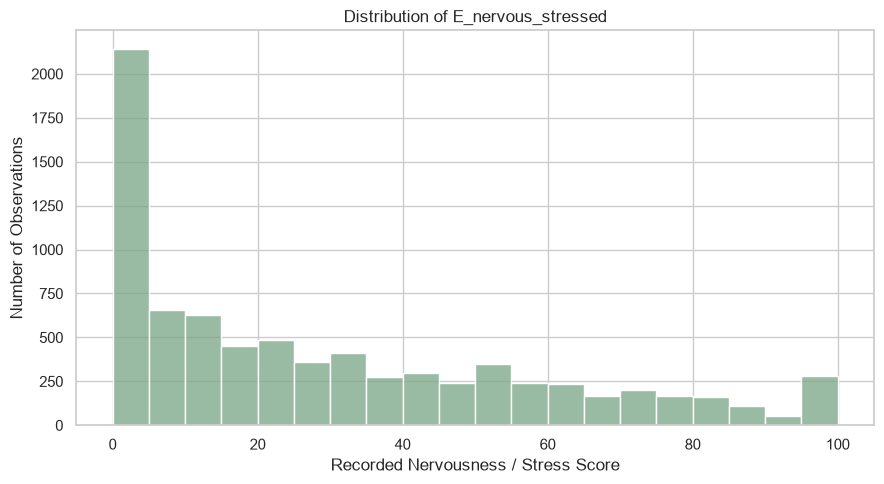

In [21]:

# ==========================================================
# STEP 20: INSPECT THE SELECTED TARGET VARIABLE
# ==========================================================

target_column = "E_nervous_stressed"
participant_column = "ID"

# Confirm the required columns exist.
assert target_column in df_clean.columns
assert participant_column in df_clean.columns

# Display target descriptive statistics.
print("TARGET VARIABLE SUMMARY:")
display(df_clean[target_column].describe())

# Examine the distinct values and their frequencies.
print("\nTARGET VALUE FREQUENCIES:")
display(
    df_clean[target_column]
    .value_counts(dropna=False)
    .sort_index()
)

# Count missing target values.
print(
    "\nMissing target values:",
    df_clean[target_column].isna().sum()
)

# Plot the target distribution.
plt.figure(figsize=(9, 5))

sns.histplot(
    df_clean[target_column].dropna(),
    bins=20,
    color="#79A584"
)

plt.title("Distribution of E_nervous_stressed")
plt.xlabel("Recorded Nervousness / Stress Score")
plt.ylabel("Number of Observations")

plt.tight_layout()
plt.show()


In [22]:

# ==========================================================
# STEP 21: PREPARE LABELLED OBSERVATIONS
# ==========================================================

# Preserve the full working dataset.
df_before_target_filter = df_clean.copy()

# Keep only rows where the target is available.
# This filtering applies only to the current
# supervised modelling experiment.
df_model = df_clean.dropna(
    subset=[target_column]
).copy()

print("Original observations:", len(df_before_target_filter))
print("Labelled observations:", len(df_model))

print(
    "Observations excluded due to missing target:",
    len(df_before_target_filter) - len(df_model)
)

print(
    "\nParticipants remaining:",
    df_model[participant_column].nunique()
)

# Verify that the modelling target has no missing values.
assert df_model[target_column].notna().all()

print("\nTarget filtering completed successfully.")


Original observations: 9792
Labelled observations: 7904
Observations excluded due to missing target: 1888

Participants remaining: 204

Target filtering completed successfully.


In [23]:

# ==========================================================
# STEP 22: PARTICIPANT-AWARE TRAIN/TEST SPLIT
# ==========================================================

from sklearn.model_selection import GroupShuffleSplit

# GroupShuffleSplit prevents the same participant
# from appearing in both training and testing sets.

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

# Split using participant IDs as grouping labels.
train_idx, test_idx = next(
    splitter.split(
        df_model,
        groups=df_model[participant_column]
    )
)

# Create separate training and testing datasets.
train_df = df_model.iloc[train_idx].copy()
test_df = df_model.iloc[test_idx].copy()

# Identify participants in each dataset.
train_participants = set(train_df[participant_column])
test_participants = set(test_df[participant_column])

print("TRAINING SET")
print("Observations:", len(train_df))
print("Participants:", len(train_participants))

print("\nTESTING SET")
print("Observations:", len(test_df))
print("Participants:", len(test_participants))

# Check whether any participant appears in both sets.
overlap = train_participants.intersection(test_participants)

print("\nOverlapping participants:", len(overlap))

assert len(overlap) == 0, (
    "Data leakage detected: participants overlap!"
)

print("\nParticipant-aware split completed successfully.")


TRAINING SET
Observations: 6350
Participants: 163

TESTING SET
Observations: 1554
Participants: 41

Overlapping participants: 0

Participant-aware split completed successfully.



### 9.2 Participant-Aware Data Splitting

The labelled dataset was divided into training and testing subsets using `GroupShuffleSplit` from scikit-learn.

The split was configured to allocate approximately:

- 80% of participants to training.
- 20% of participants to testing.

The participant identifier `ID` was used as the grouping variable.

This ensures that participants assigned to the training set do not also appear in the testing set.

### Why This Matters

A conventional random row-level split could place repeated measurements from the same participant in both datasets.

Because observations from one participant may share individual characteristics, this can produce overly optimistic evaluation results.

Participant-aware splitting provides a more appropriate test of generalization to unseen participants.

The actual numbers of participants and observations in each subset are reported by the preceding code cell.

### Next Stage

The next stage will involve selecting predictor variables, handling missing predictor values, constructing a preprocessing pipeline and training an exploratory baseline model.



## 10. Machine Learning Preprocessing and Baseline Model

### 10.1 Purpose

This stage develops an initial exploratory regression model to predict the recorded `E_nervous_stressed` measurement.

The baseline model provides a reference point against which more advanced models can later be compared.

### Preprocessing Activities

1. Select predictor variables.
2. Exclude participant identifiers and target variables from the predictors.
3. Handle missing predictor values.
4. Standardize numerical variables.
5. Encode categorical variables where appropriate.
6. Train a baseline regression model.
7. Evaluate its predictive performance.

### Preventing Data Leakage

The preprocessing pipeline will be fitted only on the training dataset.

The learned transformations will then be applied to the testing dataset.

This prevents information from the testing dataset influencing the training process.

### Limitation

The dataset has not been verified as containing a clinically defined anorexia nervosa relapse outcome. Therefore, this model is exploratory and should not be used to generate clinical risk scores.


In [24]:

# ==========================================================
# STEP 23: REVIEW CANDIDATE PREDICTOR VARIABLES
# ==========================================================

# Exclude the target and participant identifier.
excluded_columns = [
    target_column,
    participant_column
]

# Find the remaining numerical columns.
candidate_predictors = [
    col for col in train_df.select_dtypes(
        include=["number"]
    ).columns
    if col not in excluded_columns
]

print("Candidate numerical predictors:")
for col in candidate_predictors:
    print("-", col)

print("\nNumber of candidates:", len(candidate_predictors))

# Display information needed for feature review.
predictor_review = pd.DataFrame({
    "Variable": candidate_predictors,
    "Missing (%)": [
        round(train_df[col].isna().mean() * 100, 2)
        for col in candidate_predictors
    ],
    "Unique Values": [
        train_df[col].nunique(dropna=True)
        for col in candidate_predictors
    ]
})

display(predictor_review)

# IMPORTANT:
# This is a list of candidate predictors, not an
# approved feature set. Variable definitions and
# measurement timing must be reviewed before training.


Candidate numerical predictors:
- ComplianceEMA
- Age
- YearsOfEducation
- BMI_sosci
- FC
- lApV
- hApV
- lAnV
- hAnV
- lApV_1
- hApV_1
- lAnV_1
- hAnV_1
- PA
- NA
- PA_1
- NA_1
- E_cheerful
- E_enthusiastic
- E_relaxed
- E_calm
- E_irritated
- E_worried
- E_depressed
- E_bored
- E_dissatisfied
- E_tense
- SEES_Happy
- SEES_Sad
- SEES_Anger
- SEES_Anxiety
- DEBQ_emo
- EDEQ_gesamt
- lApV_cwc
- hApV_cwc
- lAnV_cwc
- hAnV_cwc
- lApV_1_cwc
- hApV_1_cwc
- lAnV_1_cwc
- hAnV_1_cwc
- NA_cwc
- PA_cwc
- NA_1_cwc
- PA_1_cwc

Number of candidates: 45


,Variable,Missing (%),Unique Values
0,ComplianceEMA,0.00,25
1,Age,0.00,38
2,YearsOfEducation,0.50,21
3,BMI_sosci,0.00,152
4,FC,0.00,101
5,lApV,0.00,200
6,hApV,0.00,193
7,lAnV,0.00,353
8,hAnV,0.00,294
9,lApV_1,20.09,197


In [29]:

# ==========================================================
# STEP 24: SELECT APPROVED PREDICTORS
# ==========================================================

# Target: stress-related emotional measurement
target_column = "E_nervous_stressed"

# Participant identifier: used for splitting only
participant_column = "ID"

# Select a small set of emotional measurements
# for our initial exploratory regression experiment.
approved_features = [
    "E_cheerful",
    "E_enthusiastic",
    "E_relaxed",
    "E_calm",
    "E_irritated",
    "E_depressed"
]

# Verify that the selected columns exist.
missing_features = [
    feature for feature in approved_features
    if feature not in train_df.columns
]

if missing_features:
    raise ValueError(
        f"Features not found: {missing_features}"
    )

# Ensure the target and participant ID are not predictors.
assert target_column not in approved_features
assert participant_column not in approved_features

# Display selected predictors.
print("SELECTED PREDICTOR VARIABLES")

for feature in approved_features:
    print("-", feature)

print("\nTotal predictors:", len(approved_features))

# Preview the training data.
display(train_df[approved_features].head())


SELECTED PREDICTOR VARIABLES
- E_cheerful
- E_enthusiastic
- E_relaxed
- E_calm
- E_irritated
- E_depressed

Total predictors: 6


,E_cheerful,E_enthusiastic,E_relaxed,E_calm,E_irritated,E_depressed
0,52.0,50.0,52.0,52.0,0.0,0.0
1,59.0,40.0,80.0,76.0,0.0,0.0
2,55.0,8.0,70.0,56.0,0.0,0.0
3,100.0,0.0,100.0,100.0,7.0,0.0
4,51.0,0.0,55.0,63.0,0.0,0.0


In [30]:

# ==========================================================
# STEP 25: BUILD AND TRAIN BASELINE MODEL
# ==========================================================

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

if not approved_features:

    print(
        "Training paused: approve predictor variables "
        "in Cell 37 before running this step."
    )

else:

    # Separate predictors and target.
    X_train = train_df[approved_features].copy()
    X_test = test_df[approved_features].copy()

    y_train = train_df[target_column].copy()
    y_test = test_df[target_column].copy()

    # This baseline currently accepts numeric features.
    non_numeric = X_train.select_dtypes(
        exclude=["number"]
    ).columns.tolist()

    if non_numeric:
        raise TypeError(
            f"Non-numeric features require encoding: {non_numeric}"
        )

    # Remove features that contain no observed
    # training values; they cannot be meaningfully
    # imputed with the training median.
    all_missing_features = X_train.columns[
        X_train.isna().all()
    ].tolist()

    if all_missing_features:
        raise ValueError(
            "These features contain only missing "
            f"training values: {all_missing_features}"
        )

    # Median imputation handles missing numeric values.
    # StandardScaler standardizes feature scales.
    # Ridge provides a regularized regression baseline.
    baseline_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0))
    ])

    # Fit preprocessing and model using training data only.
    baseline_pipeline.fit(X_train, y_train)

    # Generate predictions for unseen participants.
    y_pred = baseline_pipeline.predict(X_test)

    print("Baseline Ridge regression trained successfully.")
    print("Training observations:", len(X_train))
    print("Testing observations:", len(X_test))


Baseline Ridge regression trained successfully.
Training observations: 6350
Testing observations: 1554


In [31]:

# ==========================================================
# STEP 26: EVALUATE BASELINE MODEL
# ==========================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

if not approved_features:

    print("Evaluation paused: model has not been trained.")

else:

    # Mean Absolute Error
    mae = mean_absolute_error(y_test, y_pred)

    # Root Mean Squared Error
    rmse = np.sqrt(
        mean_squared_error(y_test, y_pred)
    )

    # Coefficient of determination
    r2 = r2_score(y_test, y_pred)

    print("BASELINE MODEL EVALUATION")
    print("-------------------------")

    print(f"MAE:  {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R²:   {r2:.4f}")

    # Compare against a simple prediction baseline:
    # always predict the training-set mean.
    mean_prediction = np.full(
        shape=len(y_test),
        fill_value=y_train.mean()
    )

    baseline_mae = mean_absolute_error(
        y_test,
        mean_prediction
    )

    print("\nTRAINING-MEAN BASELINE")
    print("----------------------")
    print(f"MAE: {baseline_mae:.4f}")


BASELINE MODEL EVALUATION
-------------------------
MAE:  15.9019
RMSE: 20.6835
R²:   0.3824

TRAINING-MEAN BASELINE
----------------------
MAE: 22.6427


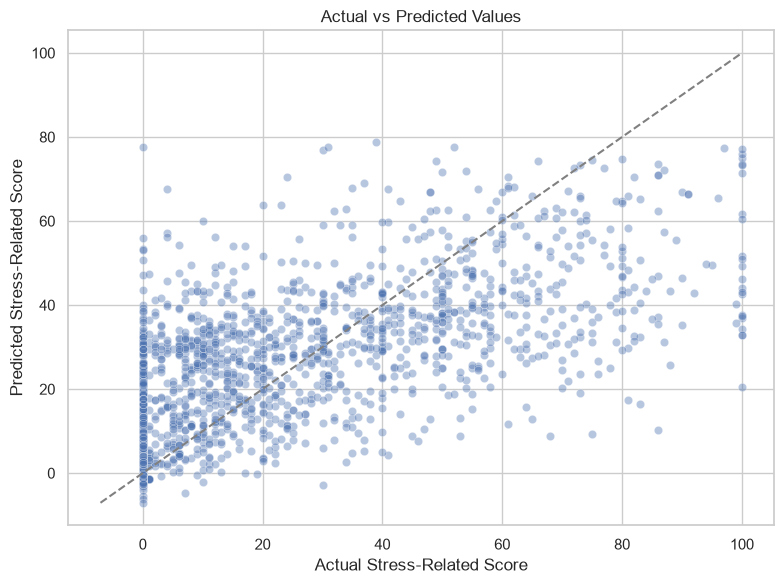

In [32]:

# ==========================================================
# STEP 27: VISUALIZE ACTUAL VS PREDICTED VALUES
# ==========================================================

if not approved_features:

    print("Visualization paused: model not trained.")

else:

    plt.figure(figsize=(8, 6))

    sns.scatterplot(
        x=y_test,
        y=y_pred,
        alpha=0.4
    )

    # Reference line for perfect predictions.
    lower = min(y_test.min(), y_pred.min())
    upper = max(y_test.max(), y_pred.max())

    plt.plot(
        [lower, upper],
        [lower, upper],
        linestyle="--",
        color="gray"
    )

    plt.xlabel("Actual Stress-Related Score")
    plt.ylabel("Predicted Stress-Related Score")
    plt.title("Actual vs Predicted Values")

    plt.tight_layout()
    plt.show()



## 11. Baseline Model Evaluation and Interpretation

### 11.1 Evaluation Results

The exploratory Ridge Regression model was evaluated on a participant-held-out testing dataset.

| Evaluation Metric | Result |
|---|---:|
| Mean Absolute Error (MAE) | 15.9019 |
| Root Mean Squared Error (RMSE) | 20.6835 |
| R-squared (R²) | 0.3824 |
| Training-Mean Baseline MAE | 22.6427 |
| Relative MAE Reduction | 29.8% |

### 11.2 Interpretation

The Ridge Regression model achieved an MAE of approximately 15.90, compared with 22.64 for the training-mean baseline.

This represents an approximate 29.8% reduction in average absolute prediction error.

The R² value of 0.3824 indicates that the model accounts for approximately 38.24% of the variation in the test-set target measurements relative to a constant-mean benchmark.

The RMSE of 20.68 indicates that larger prediction errors remain a concern.

### 11.3 Limitations

- The model predicts a stress-related measurement, not anorexia nervosa relapse.
- The selected emotional predictors may be recorded at the same assessment as the target.
- The model has not been established as a future forecasting model.
- The evaluation is based on one participant-aware split.
- Further validation and comparison with alternative models are necessary.

### 11.4 Conclusion

The exploratory Ridge Regression model demonstrates that the selected emotional measurements contain predictive information about the recorded stress-related target.

However, the model requires further evaluation before its results can be considered reliable for practical use.



## 12. Random Forest Regression

### 12.1 Introduction

Random Forest is an ensemble machine-learning algorithm that combines predictions from multiple decision trees.

Unlike Ridge Regression, which models a linear relationship between predictors and the target, Random Forest can learn nonlinear relationships and interactions between variables.

### Why Compare Random Forest with Ridge Regression?

- Ridge Regression provides a regularized linear baseline.
- Random Forest can capture more complex relationships.
- Comparing both models helps determine whether additional model complexity improves predictive performance.

### Experimental Setup

Both models use:

- The same six emotional predictor variables.
- The same stress-related target (`E_nervous_stressed`).
- The same participant-aware training and testing sets.
- The same evaluation metrics: MAE, RMSE and R².

### Important Limitation

This experiment predicts a stress-related emotional measurement. It does not predict clinically validated anorexia nervosa relapse risk.


In [33]:

# ==========================================================
# STEP 28: TRAIN RANDOM FOREST REGRESSION MODEL
# ==========================================================

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Create the Random Forest pipeline.
# Median imputation is retained for consistency
# and to handle any missing numerical predictors.
#
# Random Forest does not require StandardScaler
# because tree-based models split on feature values.

rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),

    ("model", RandomForestRegressor(
        n_estimators=100,     # Number of decision trees
        max_depth=8,         # Limit tree complexity
        min_samples_leaf=5,  # Require at least 5 rows per leaf
        random_state=42,
        n_jobs=-1
    ))
])

# Train on the SAME training data used for Ridge.
rf_pipeline.fit(X_train, y_train)

# Predict on the SAME held-out testing data.
rf_predictions = rf_pipeline.predict(X_test)

print("Random Forest trained successfully!")
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Number of predictors:", X_train.shape[1])


Random Forest trained successfully!
Training observations: 6350
Testing observations: 1554
Number of predictors: 6


In [34]:

# ==========================================================
# STEP 29: EVALUATE RANDOM FOREST
# ==========================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Calculate evaluation metrics.
rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

rf_r2 = r2_score(y_test, rf_predictions)

print("RANDOM FOREST EVALUATION")
print("------------------------")

print(f"MAE:  {rf_mae:.4f}")
print(f"RMSE: {rf_rmse:.4f}")
print(f"R²:   {rf_r2:.4f}")


RANDOM FOREST EVALUATION
------------------------
MAE:  15.8943
RMSE: 20.8752
R²:   0.3709


In [35]:

# ==========================================================
# STEP 30: COMPARE BOTH MODELS
# ==========================================================

comparison_df = pd.DataFrame({
    "Model": [
        "Ridge Regression",
        "Random Forest"
    ],
    "MAE": [
        mae,
        rf_mae
    ],
    "RMSE": [
        rmse,
        rf_rmse
    ],
    "R²": [
        r2,
        rf_r2
    ]
})

print("MODEL COMPARISON")
display(comparison_df.round(4))

# Select the model with the lowest MAE.
# This is a descriptive comparison on the test set,
# not a substitute for validation-based model selection.
best_model_name = comparison_df.loc[
    comparison_df["MAE"].idxmin(),
    "Model"
]

print("Lowest test MAE:", best_model_name)


MODEL COMPARISON


,Model,MAE,RMSE,R²
0,Ridge Regression,15.9019,20.6835,0.3824
1,Random Forest,15.8943,20.8752,0.3709


Lowest test MAE: Random Forest



## 13. Model Comparison and Interpretation

### 13.1 Results

Two exploratory regression models were evaluated using the same participant-held-out testing dataset.

| Metric | Ridge Regression | Random Forest |
|---|---:|---:|
| MAE | 15.9019 | 15.8943 |
| RMSE | 20.6835 | 20.8752 |
| R² | 0.3824 | 0.3709 |

### 13.2 Interpretation

Random Forest achieved a marginally lower MAE than Ridge Regression, with a difference of only 0.0076.

However, Ridge Regression achieved a lower RMSE and a higher R².

The results suggest that the additional complexity of Random Forest did not produce a substantial improvement in predictive performance in this experiment.

Ridge Regression remains a reasonable baseline because of its relative simplicity and comparable performance.

### 13.3 Research Implications

The selected emotional measurements provide some predictive information about the stress-related target.

However, the results do not establish:

- Prediction of future emotional states.
- Detection of anorexia nervosa relapse.
- Clinical reliability or diagnostic accuracy.
- Generalization across all populations.

### 13.4 Further Validation

Before selecting a final model, participant-grouped cross-validation should be performed using the training dataset.

The held-out test set should then be reserved for final evaluation of the selected model.


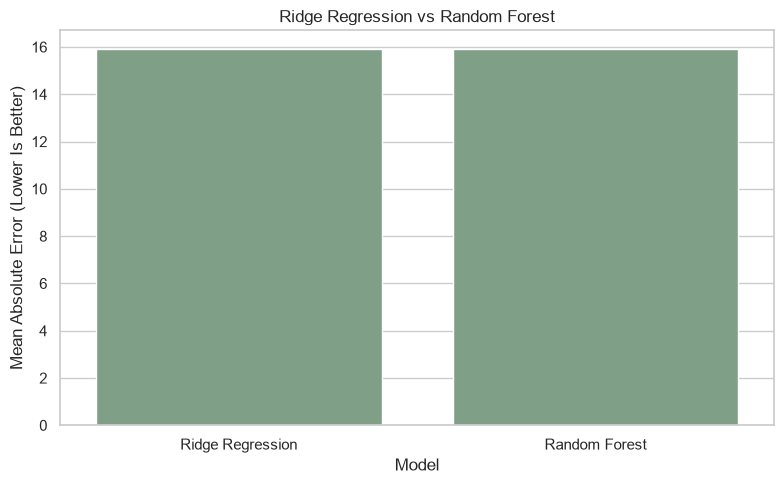

In [36]:

# ==========================================================
# STEP 31: VISUALIZE MODEL PERFORMANCE
# ==========================================================

plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="MAE",
    color="#79A584"
)

plt.title("Ridge Regression vs Random Forest")
plt.ylabel("Mean Absolute Error (Lower Is Better)")
plt.xlabel("Model")

plt.tight_layout()
plt.show()


In [37]:

# ==========================================================
# STEP 32: CHECK FOR OVERFITTING
# ==========================================================

from sklearn.metrics import mean_absolute_error, r2_score

# Generate predictions on training data.
ridge_train_predictions = baseline_pipeline.predict(X_train)
rf_train_predictions = rf_pipeline.predict(X_train)

# Evaluate both models on training and testing data.
overfitting_results = pd.DataFrame({
    "Model": ["Ridge Regression", "Random Forest"],

    "Training MAE": [
        mean_absolute_error(y_train, ridge_train_predictions),
        mean_absolute_error(y_train, rf_train_predictions)
    ],

    "Testing MAE": [
        mean_absolute_error(y_test, y_pred),
        mean_absolute_error(y_test, rf_predictions)
    ],

    "Training R²": [
        r2_score(y_train, ridge_train_predictions),
        r2_score(y_train, rf_train_predictions)
    ],

    "Testing R²": [
        r2_score(y_test, y_pred),
        r2_score(y_test, rf_predictions)
    ]
})

# Calculate the difference between test and train errors.
overfitting_results["MAE Gap"] = (
    overfitting_results["Testing MAE"]
    - overfitting_results["Training MAE"]
)

print("TRAINING VS TESTING PERFORMANCE")
display(overfitting_results.round(4))


TRAINING VS TESTING PERFORMANCE


,Model,Training MAE,Testing MAE,Training R²,Testing R²,MAE Gap
0,Ridge Regression,16.8068,15.9019,0.4326,0.3824,-0.9049
1,Random Forest,14.5398,15.8943,0.5535,0.3709,1.3544



## 14. Participant-Grouped Cross-Validation

### 14.1 Introduction

Cross-validation is a model evaluation technique that divides training data into multiple subsets, called folds.

The model is trained on some folds and evaluated on the remaining fold. This process is repeated so that each fold is used for validation.

### Why Cross-Validation?

A single training/testing split may produce results influenced by the particular observations or participants selected.

Cross-validation provides additional evidence about model performance across different subsets of the training data.

### Why GroupKFold?

The EMA dataset contains repeated observations from individual participants.

Using ordinary K-Fold cross-validation could place observations from the same participant in both the training and validation folds.

GroupKFold prevents this by keeping each participant within one fold.

### Experimental Design

- Cross-validation method: GroupKFold
- Number of folds: 5
- Grouping variable: ID
- Models: Ridge Regression and Random Forest
- Evaluation metrics: MAE, RMSE and R²

Cross-validation will be performed on the training dataset only.

The previously held-out testing dataset will not be used during cross-validation.

### Important Limitation

The experiment evaluates prediction of a stress-related measurement, not clinical anorexia nervosa relapse.


In [38]:

# ==========================================================
# STEP 33: PARTICIPANT-GROUPED CROSS-VALIDATION
# ==========================================================

from sklearn.model_selection import GroupKFold, cross_validate

# Use the same six approved predictors.
X_cv = train_df[approved_features].copy()

# Use the same exploratory target.
y_cv = train_df[target_column].copy()

# Identify participants for grouping.
groups_cv = train_df[participant_column].copy()

# Create five participant-grouped folds.
group_kfold = GroupKFold(n_splits=5)

# Define the models to compare.
models = {
    "Ridge Regression": baseline_pipeline,
    "Random Forest": rf_pipeline
}

# Store the cross-validation results.
cv_results = []

for model_name, model in models.items():

    print(f"\nEvaluating: {model_name}")

    # cross_validate fits a fresh copy of the pipeline
    # in each fold. This means imputation and scaling
    # are learned from that fold's training data only.
    scores = cross_validate(
        estimator=model,
        X=X_cv,
        y=y_cv,
        groups=groups_cv,
        cv=group_kfold,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        },
        n_jobs=1
    )

    # Scikit-learn returns negative values for
    # error metrics because higher scores are
    # conventionally treated as better.
    # Convert them back to positive errors.
    fold_mae = -scores["test_MAE"]
    fold_rmse = -scores["test_RMSE"]
    fold_r2 = scores["test_R2"]

    # Store one record for each validation fold.
    for fold_number in range(5):

        cv_results.append({
            "Model": model_name,
            "Fold": fold_number + 1,
            "MAE": fold_mae[fold_number],
            "RMSE": fold_rmse[fold_number],
            "R²": fold_r2[fold_number]
        })

# Convert results into a DataFrame.
cv_results_df = pd.DataFrame(cv_results)

print("\nCROSS-VALIDATION RESULTS")
display(cv_results_df.round(4))



Evaluating: Ridge Regression

Evaluating: Random Forest

CROSS-VALIDATION RESULTS


,Model,Fold,MAE,RMSE,R²
0,Ridge Regression,1,18.1051,24.5055,0.4066
1,Ridge Regression,2,19.8862,25.4261,0.2954
2,Ridge Regression,3,14.2863,18.9479,0.4671
3,Ridge Regression,4,17.4397,21.5963,0.4759
4,Ridge Regression,5,15.3926,19.9601,0.4423
5,Random Forest,1,17.7605,24.6066,0.4017
6,Random Forest,2,20.7972,27.3995,0.1818
7,Random Forest,3,14.4941,19.4913,0.4361
8,Random Forest,4,17.2195,21.6563,0.4730
9,Random Forest,5,15.4363,20.7682,0.3963


In [39]:

# ==========================================================
# STEP 34: SUMMARIZE CROSS-VALIDATION RESULTS
# ==========================================================

# Calculate the mean and standard deviation
# of each evaluation metric across five folds.
cv_summary = (
    cv_results_df
    .groupby("Model")
    .agg(
        Mean_MAE=("MAE", "mean"),
        Std_MAE=("MAE", "std"),
        Mean_RMSE=("RMSE", "mean"),
        Std_RMSE=("RMSE", "std"),
        Mean_R2=("R²", "mean"),
        Std_R2=("R²", "std")
    )
    .reset_index()
)

print("AVERAGE CROSS-VALIDATION PERFORMANCE")

display(cv_summary.round(4))


AVERAGE CROSS-VALIDATION PERFORMANCE


,Model,Mean_MAE,Std_MAE,Mean_RMSE,Std_RMSE,Mean_R2,Std_R2
0,Random Forest,17.1415,2.4326,22.7843,3.1938,0.3778,0.1138
1,Ridge Regression,17.0220,2.2187,22.0872,2.8114,0.4175,0.0733



## 15. Model Selection and Final Evaluation

### 15.1 Model Selection

Two regression algorithms were compared:

1. Ridge Regression
2. Random Forest Regression

Both models were evaluated using five-fold participant-grouped cross-validation on the training dataset.

### Cross-Validation Results

| Metric | Ridge Regression | Random Forest |
|---|---:|---:|
| Mean MAE | 17.0220 | 17.1415 |
| Mean RMSE | 22.0872 | 22.7843 |
| Mean R² | 0.4175 | 0.3778 |
| Standard Deviation of MAE | 2.2187 | 2.4326 |
| Standard Deviation of R² | 0.0733 | 0.1138 |

### Selected Model: Ridge Regression

Ridge Regression was selected as the preferred exploratory baseline because:

- It achieved lower average prediction errors.
- It produced a higher average R².
- It showed more consistent performance across validation folds.
- It is relatively simple and interpretable.

### Important Considerations

The performance differences between the two models are modest.

The model selection is based on predictive performance for the stress-related target `E_nervous_stressed`.

The selected model does not predict clinically defined anorexia nervosa relapse.

The emotional predictors may have been measured at the same time as the target, so this experiment does not yet demonstrate future forecasting.


In [40]:

# ==========================================================
# STEP 35: FINAL EVALUATION OF SELECTED MODEL
# ==========================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Ridge Regression was selected based on the
# participant-grouped cross-validation results.
selected_model = baseline_pipeline

# Predict using the existing held-out testing data.
# Do not refit the model using testing observations.
final_predictions = selected_model.predict(X_test)

# Calculate final evaluation metrics.
final_mae = mean_absolute_error(
    y_test, final_predictions
)

final_rmse = np.sqrt(
    mean_squared_error(y_test, final_predictions)
)

final_r2 = r2_score(
    y_test, final_predictions
)

print("FINAL SELECTED MODEL: RIDGE REGRESSION")
print("--------------------------------------")

print(f"MAE:  {final_mae:.4f}")
print(f"RMSE: {final_rmse:.4f}")
print(f"R²:   {final_r2:.4f}")

print("\nSelected features:")
for feature in approved_features:
    print("-", feature)

print("\nTraining participants:",
      train_df[participant_column].nunique())

print("Testing participants:",
      test_df[participant_column].nunique())


FINAL SELECTED MODEL: RIDGE REGRESSION
--------------------------------------
MAE:  15.9019
RMSE: 20.6835
R²:   0.3824

Selected features:
- E_cheerful
- E_enthusiastic
- E_relaxed
- E_calm
- E_irritated
- E_depressed

Training participants: 163
Testing participants: 41



## 16. Model Persistence and Backend Integration

### 16.1 Introduction

Model persistence refers to saving a trained machine-learning model so that it can be reused without repeating the entire training process.

For MindBloom, the selected exploratory model is Ridge Regression.

The model was selected based on five-fold participant-grouped cross-validation.

### Why Save the Model?

Saving the model allows us to:

1. Preserve the trained model and its preprocessing steps.
2. Reuse the model without retraining.
3. Test predictions using new input observations.
4. Prepare for possible integration with the Django backend.
5. Maintain a reproducible machine-learning workflow.

### Saving the Complete Pipeline

The Ridge Regression model was trained using a scikit-learn Pipeline containing:

- SimpleImputer for handling missing numerical values.
- StandardScaler for standardizing predictors.
- Ridge Regression for predicting the target.

Saving the complete pipeline ensures that the same preprocessing transformations are applied when making future predictions.

### Research Limitation

The saved model is an exploratory stress-related prediction model.

It is not a clinically validated anorexia nervosa relapse-risk prediction system and must not be used to generate clinical relapse alerts.


In [41]:

# ==========================================================
# STEP 36: SAVE THE SELECTED RIDGE REGRESSION MODEL
# ==========================================================

from pathlib import Path
import joblib
import json
import sklearn

# Identify the MindBloom project directory.
# The notebook is stored inside the notebooks folder.
project_root = Path.cwd().parent

# Store exploratory models separately from clinical
# or production application functionality.
model_directory = (
    project_root / "core" / "ml" / "models"
)

# Create the folder if it does not exist.
model_directory.mkdir(
    parents=True,
    exist_ok=True
)

# Define the saved model's filename.
model_path = (
    model_directory / "mindbloom_stress_ridge.joblib"
)

# Save the entire trained preprocessing pipeline.
joblib.dump(
    baseline_pipeline,
    model_path
)

# Save metadata describing the model and its inputs.
model_metadata = {
    "model_name": "MindBloom Exploratory Stress Ridge",
    "model_type": "Ridge Regression",
    "target": target_column,
    "features": approved_features,
    "participant_id": participant_column,
    "purpose": "Exploratory stress-related prediction",
    "clinical_relapse_model": False,
    "sklearn_version": sklearn.__version__
}

metadata_path = (
    model_directory / "mindbloom_stress_ridge_metadata.json"
)

with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(
        model_metadata,
        file,
        indent=4
    )

print("MODEL SAVED SUCCESSFULLY")
print("Model path:", model_path)
print("Metadata path:", metadata_path)


MODEL SAVED SUCCESSFULLY
Model path: C:\Users\sigei\OneDrive\Documents\Year 4\4.2\IS Project II\MindBloom-System\core\ml\models\mindbloom_stress_ridge.joblib
Metadata path: C:\Users\sigei\OneDrive\Documents\Year 4\4.2\IS Project II\MindBloom-System\core\ml\models\mindbloom_stress_ridge_metadata.json


In [42]:

# ==========================================================
# STEP 37: VERIFY SAVED MODEL
# ==========================================================

import numpy as np

# Load the model saved in the previous cell.
loaded_model = joblib.load(model_path)

# Select the first five testing observations.
sample_inputs = X_test.head(5).copy()

# Generate predictions using the original pipeline.
original_predictions = baseline_pipeline.predict(
    sample_inputs
)

# Generate predictions using the loaded pipeline.
loaded_predictions = loaded_model.predict(
    sample_inputs
)

# Compare both sets of predictions.
verification_results = pd.DataFrame({
    "Original Prediction": original_predictions,
    "Loaded Model Prediction": loaded_predictions
})

display(verification_results)

# Verify that saving and loading preserved predictions.
assert np.allclose(
    original_predictions,
    loaded_predictions
)

print("Model verification successful!")
print("Saved and loaded predictions match.")


,Original Prediction,Loaded Model Prediction
0,33.828728,33.828728
1,51.111458,51.111458
2,47.416052,47.416052
3,37.816170,37.816170
4,26.306326,26.306326


Model verification successful!
Saved and loaded predictions match.
